In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Data Quality

In [5]:
df = pd.read_excel('Telco_customer_churn.xlsx')

In [6]:
df.isnull().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


In [7]:
df['Churn Value'].value_counts()

,count
Churn Value,
0,5174
1,1869


Data is clean with only missing values being located in Churn Reason. These values are missing for customers who have not churned. The churn class is heavily imbalanced, with only 26.54% of customers churning.

In [8]:
print(df.dtypes)

CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Label           object
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object


In [9]:
# Check for duplicate customers
df['CustomerID'].duplicated().sum()

np.int64(0)

In [10]:
df['Total Charges'].describe()

,Total Charges
count,7043.0
unique,6531.0
top,20.2
freq,11.0


In [11]:
# Check Total Charges to see if it should actually be object
df['Total Charges'].head(50).values

array([108.15, 151.65, 820.5, 3046.05, 5036.3, 528.35, 39.65, 20.15,
       4749.15, 30.2, 1093.1, 316.9, 3549.25, 1105.4, 144.15, 1426.4,
       633.3, 1752.55, 857.25, 79.35, 496.9, 927.35, 113.85, 2514.5,
       7611.85, 5238.9, 2868.15, 1064.65, 229.55, 2135.5, 1502.65, 35.45,
       81.25, 70.45, 563.65, 45.65, 655.5, 1592.35, 273, 2651.2, 242.8,
       5000.2, 1145.7, 503.6, 29.95, 662.65, 1111.65, 24.8, 531, 79.9],
      dtype=object)

Based on these values, Total Charges should be a numeric column rather than an object.

In [12]:
# Convert Total Charges to be numeric instead of object, fill resulting na from blank string with 0
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df['Total Charges'] = df['Total Charges'].fillna(0)

In [13]:
# Check unique values per column
print(df.nunique())

CustomerID           7043
Count                   1
Country                 1
State                   1
City                 1129
Zip Code             1652
Lat Long             1652
Latitude             1652
Longitude            1651
Gender                  2
Senior Citizen          2
Partner                 2
Dependents              2
Tenure Months          73
Phone Service           2
Multiple Lines          3
Internet Service        3
Online Security         3
Online Backup           3
Device Protection       3
Tech Support            3
Streaming TV            3
Streaming Movies        3
Contract                3
Paperless Billing       2
Payment Method          4
Monthly Charges      1585
Total Charges        6531
Churn Label             2
Churn Value             2
Churn Score            85
CLTV                 3438
Churn Reason           20
dtype: int64


In [14]:
# Look at categorical unique values
categorical_cols = [
    'Gender',
    'Senior Citizen',
    'Partner',
    'Dependents',
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Contract',
    'Paperless Billing',
    'Payment Method',
]

numeric_cols = ['Tenure Months', 'Total Charges', 'Monthly Charges']

for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(df[col].unique())


--- Gender ---
['Male' 'Female']

--- Senior Citizen ---
['No' 'Yes']

--- Partner ---
['No' 'Yes']

--- Dependents ---
['No' 'Yes']

--- Phone Service ---
['Yes' 'No']

--- Multiple Lines ---
['No' 'Yes' 'No phone service']

--- Internet Service ---
['DSL' 'Fiber optic' 'No']

--- Online Security ---
['Yes' 'No' 'No internet service']

--- Online Backup ---
['Yes' 'No' 'No internet service']

--- Device Protection ---
['No' 'Yes' 'No internet service']

--- Tech Support ---
['No' 'Yes' 'No internet service']

--- Streaming TV ---
['No' 'Yes' 'No internet service']

--- Streaming Movies ---
['No' 'Yes' 'No internet service']

--- Contract ---
['Month-to-month' 'Two year' 'One year']

--- Paperless Billing ---
['Yes' 'No']

--- Payment Method ---
['Mailed check' 'Electronic check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [15]:
for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(df[col].value_counts(dropna=False))


--- Gender ---
Gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Senior Citizen ---
Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     5416
Yes    1627
Name: count, dtype: int64

--- Phone Service ---
Phone Service
Yes    6361
No      682
Name: count, dtype: int64

--- Multiple Lines ---
Multiple Lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- Internet Service ---
Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- Online Security ---
Online Security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- Online Backup ---
Online Backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- Device Protection

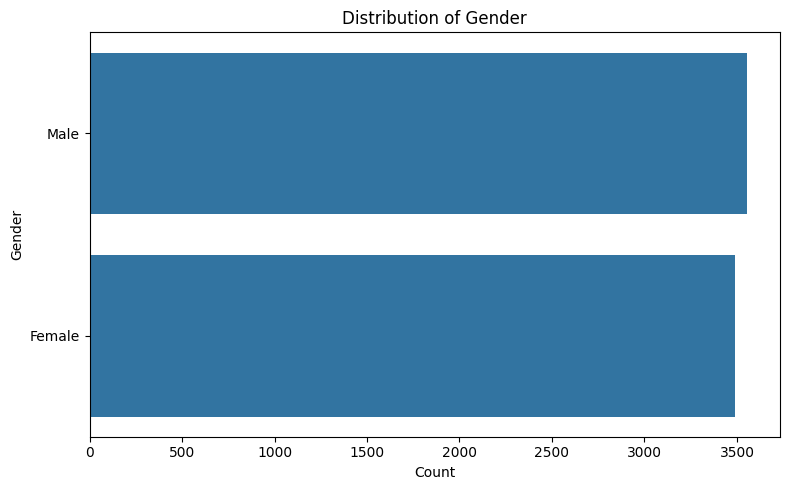

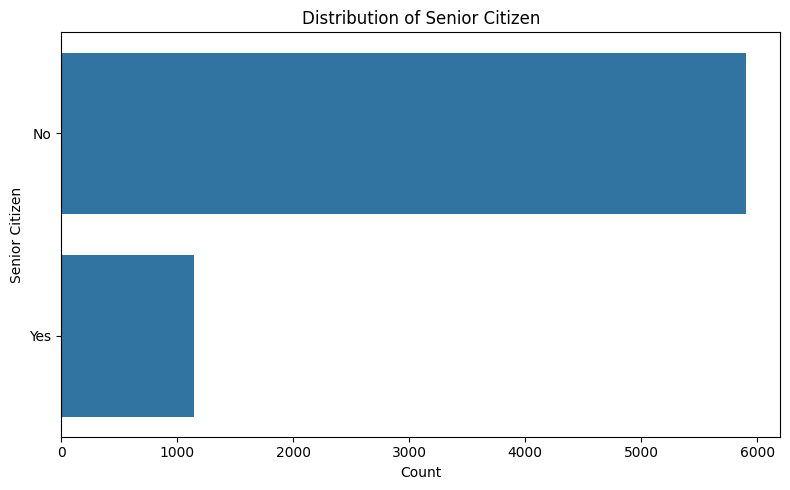

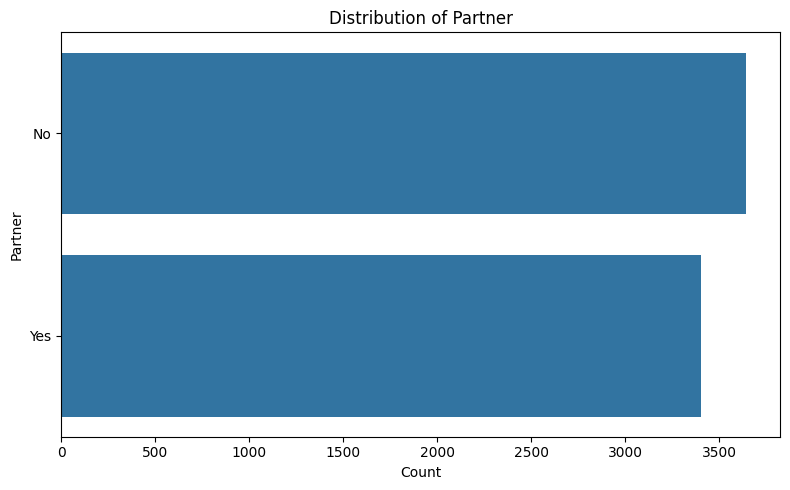

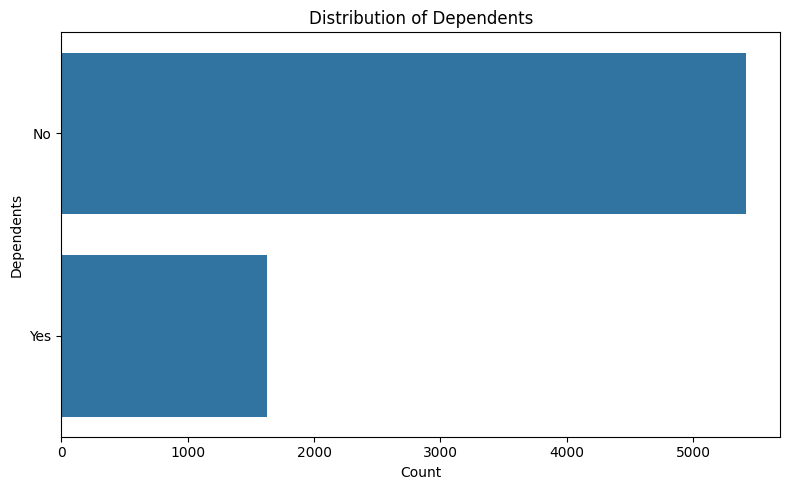

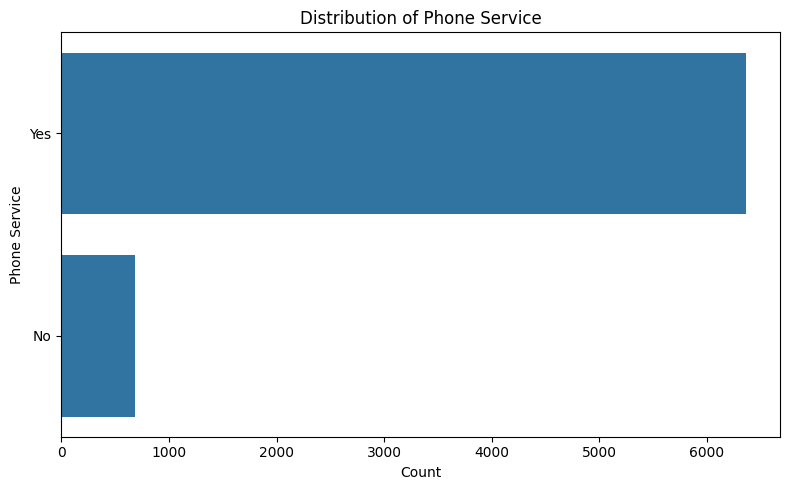

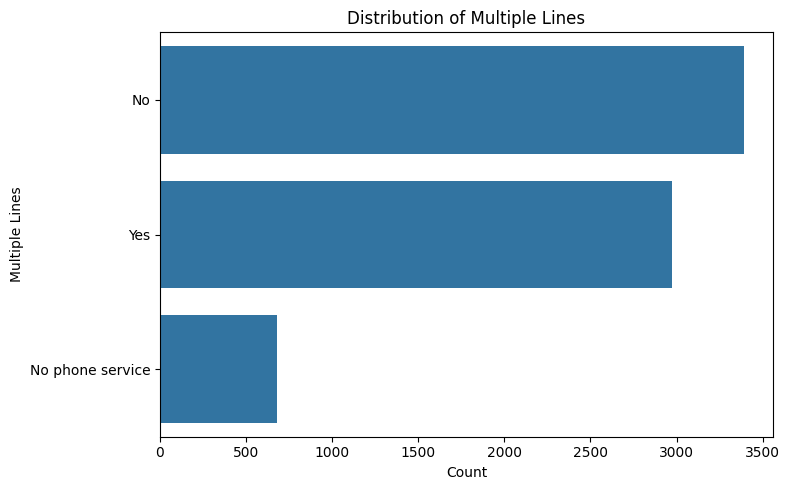

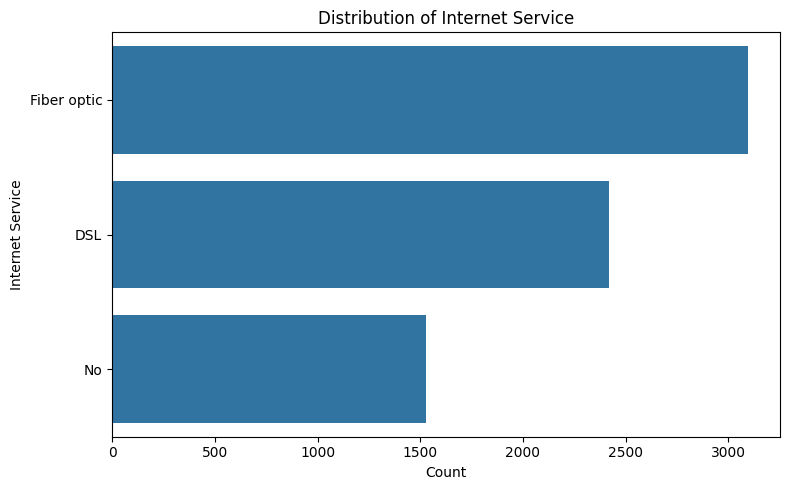

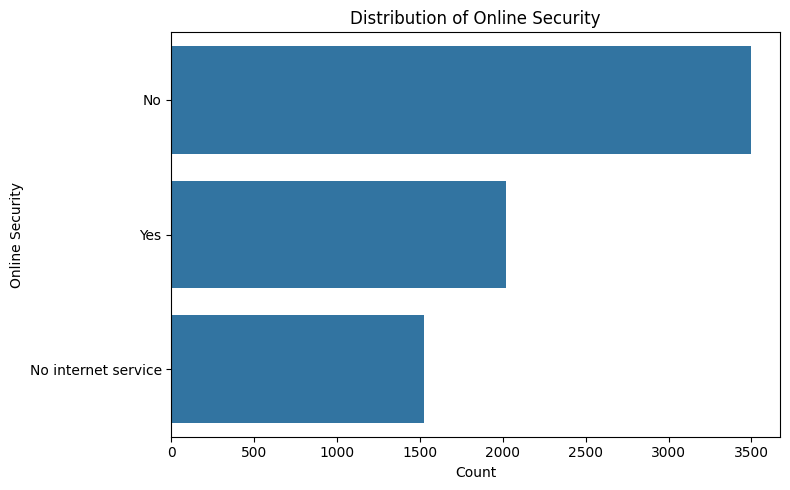

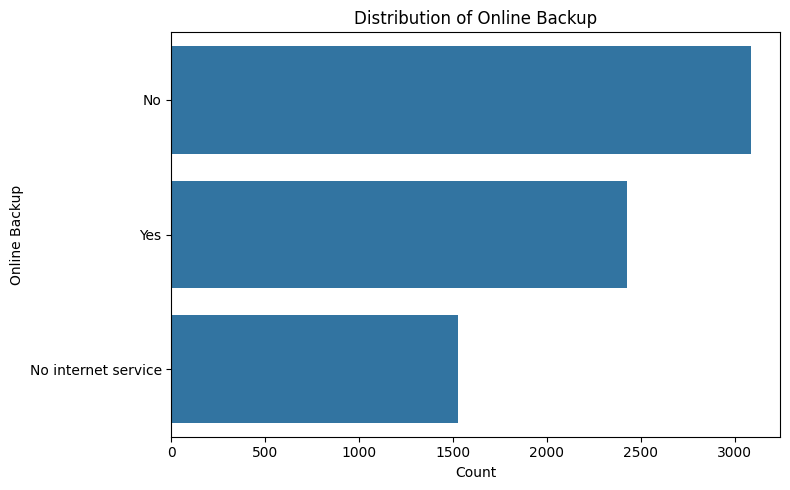

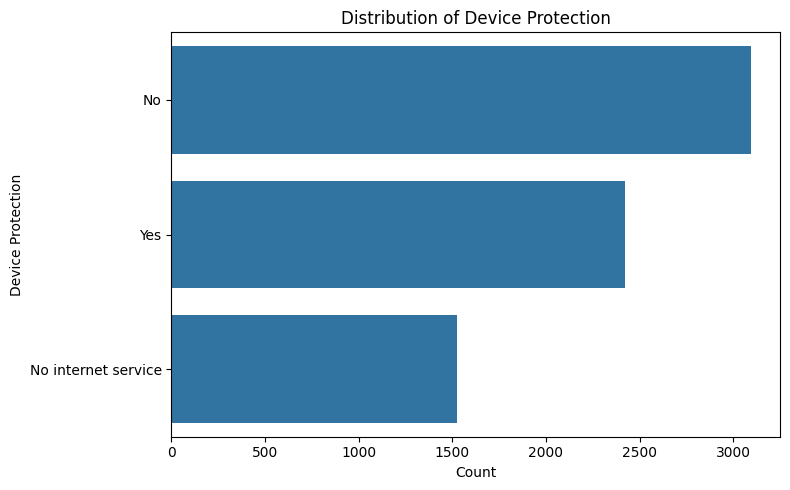

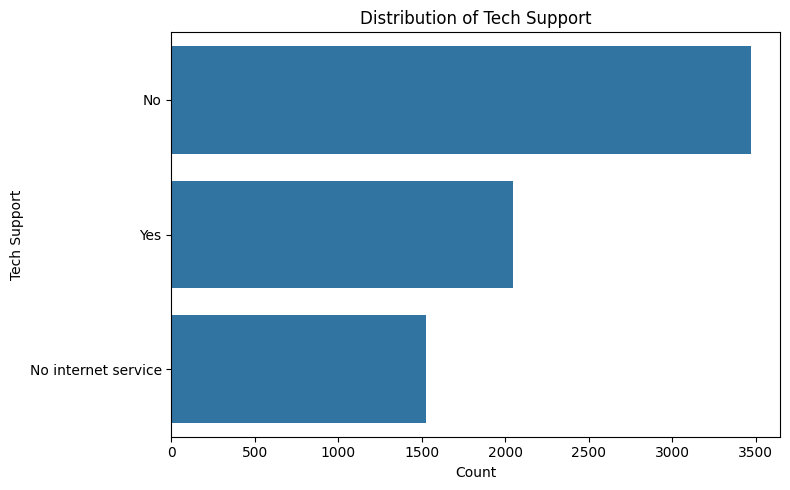

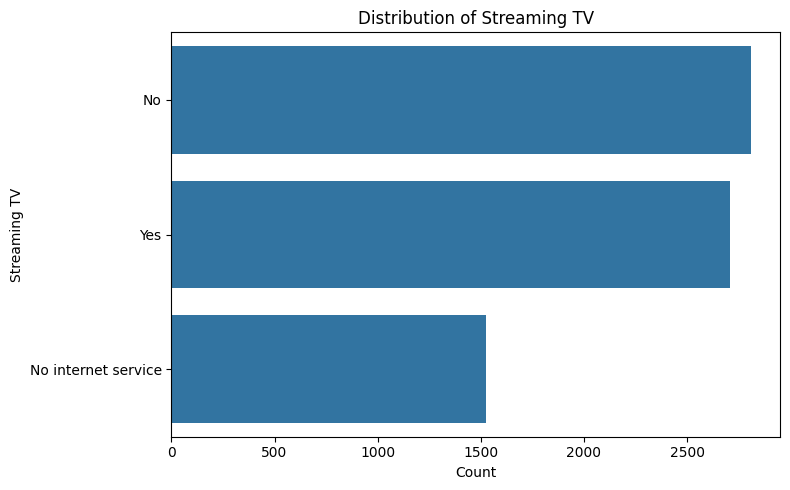

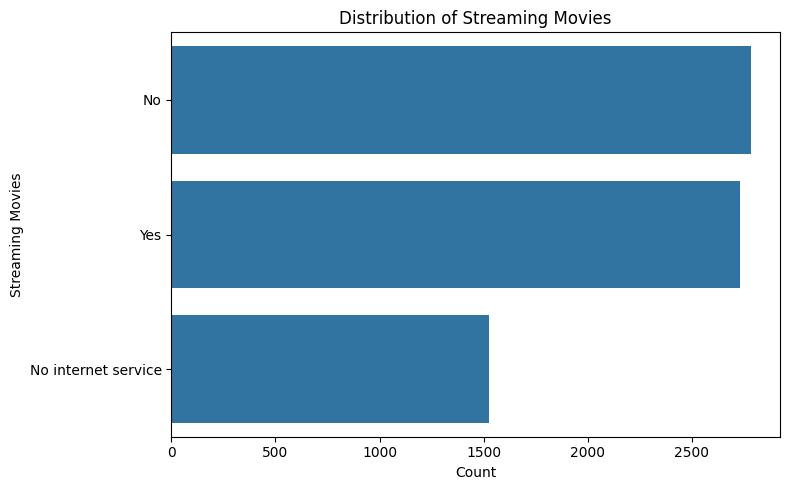

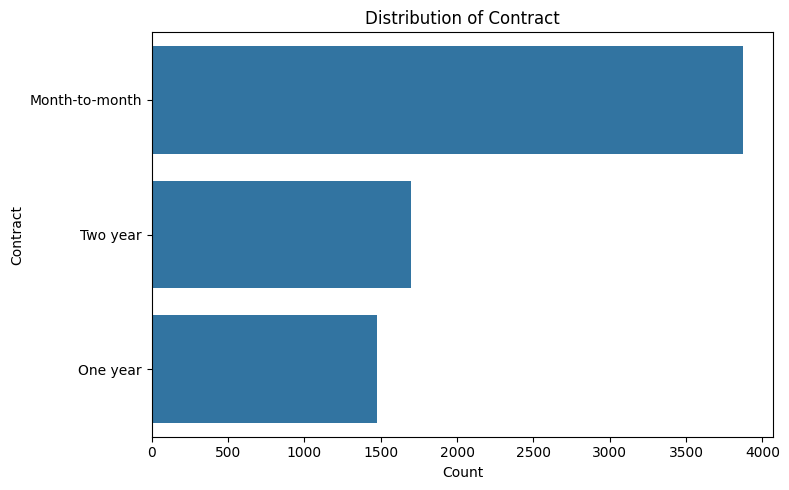

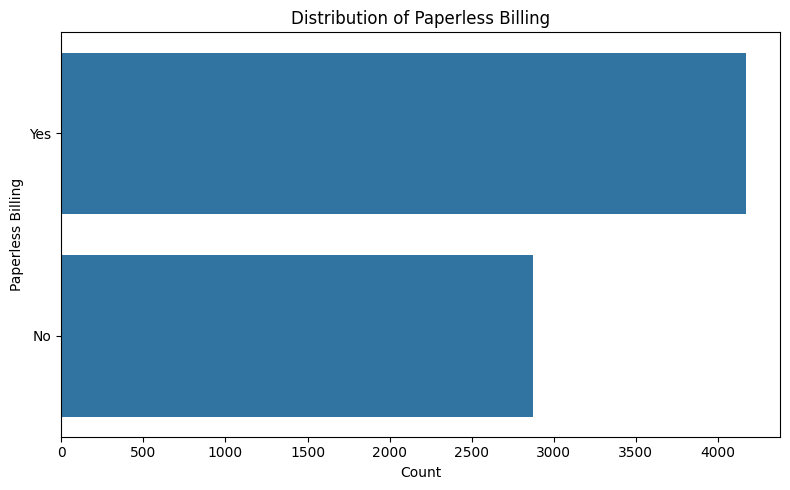

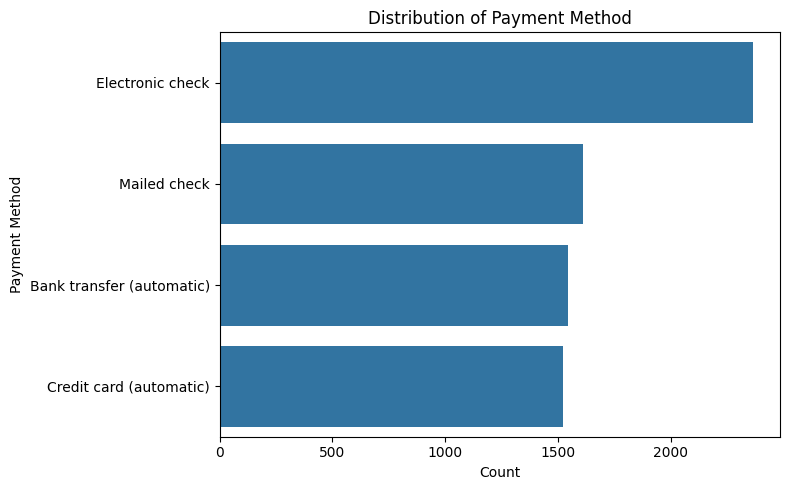

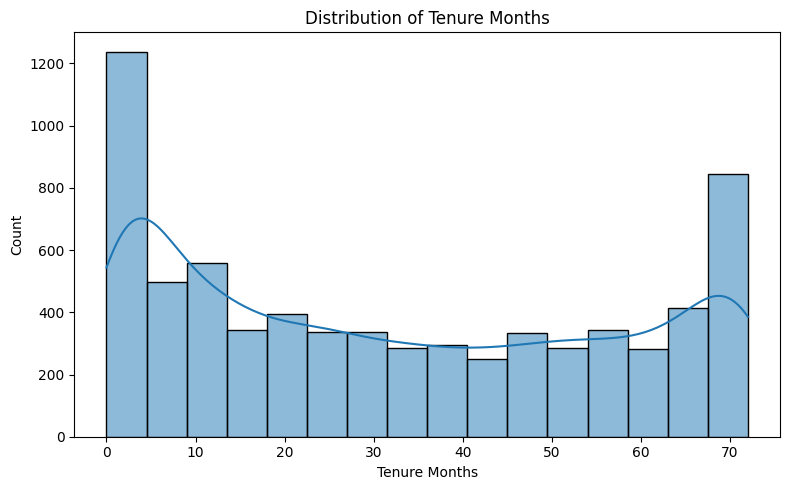

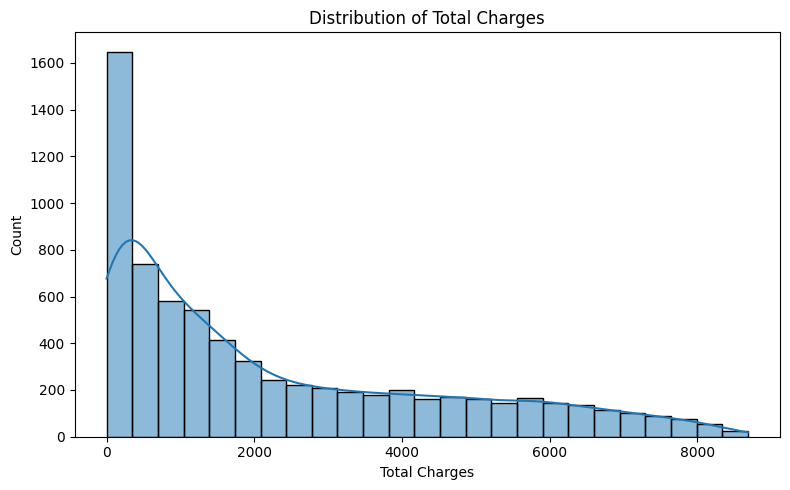

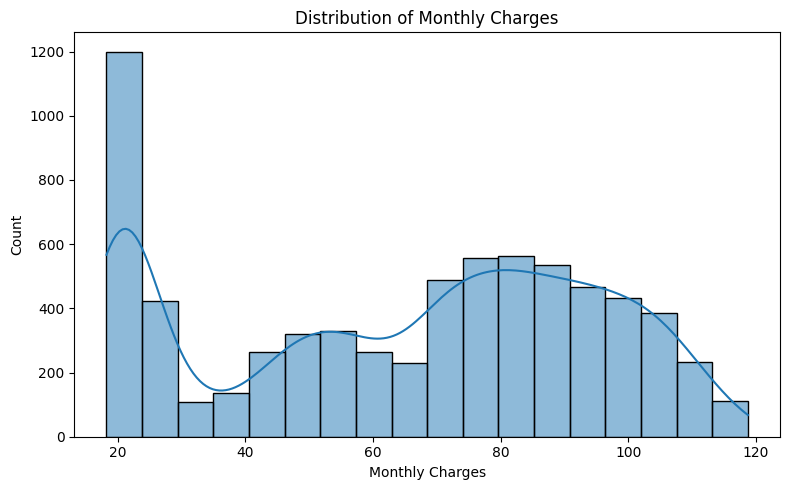

In [16]:
# Plot every column to view distributions
for col in df[categorical_cols + numeric_cols].columns:

    # Skip columns with no data
    if df[col].dropna().empty:
        continue

    plt.figure(figsize=(8, 5))

    # Numeric columns
    if pd.api.types.is_numeric_dtype(df[col]):
        sns.histplot(df[col].dropna(), kde=True)
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Count')

    # Categorical columns
    else:
        # Get category counts
        counts = df[col].fillna('Missing').value_counts()

        # Limit extremely high-cardinality variables
        if len(counts) > 20:
            counts = counts.head(20)
            title = f'Top 20 Categories of {col}'
        else:
            title = f'Distribution of {col}'

        sns.barplot(x=counts.values, y=counts.index)
        plt.title(title)
        plt.xlabel('Count')
        plt.ylabel(col)

    plt.tight_layout()
    plt.show()

# Churn Distributions Investigation

In [17]:
print(df['Churn Label'].value_counts())
print(f"\nPercentage of customers who churn: {100 * df['Churn Value'].mean():.2f}%")

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Percentage of customers who churn: 26.54%


## Customer Characteristics and Their Relation to Churn

In [18]:
city_churn = (
    df.groupby('City')
      .agg(
          Customers=('Churn Value', 'size'),
          Churn_Rate=('Churn Value', 'mean')
      )
)

city_churn['Churn_Rate'] = city_churn['Churn_Rate'] * 100

city_churn = city_churn.sort_values(
    'Churn_Rate',
    ascending=False
)

print(city_churn[city_churn['Customers'] > 20].head(40))

                Customers  Churn_Rate
City                                 
Santa Rosa             24   45.833333
Modesto                28   42.857143
Santa Barbara          28   35.714286
San Diego             150   33.333333
Glendale               40   32.500000
Torrance               25   32.000000
Pasadena               30   30.000000
San Francisco         104   29.807692
Los Angeles           305   29.508197
San Bernardino         28   28.571429
Berkeley               32   28.125000
Stockton               44   27.272727
San Jose              112   25.892857
Riverside              32   25.000000
Long Beach             60   25.000000
Fresno                 64   25.000000
Oakland                52   25.000000
Anaheim                28   25.000000
Santa Ana              24   25.000000
Sacramento            108   24.074074
Burbank                25   24.000000
Inglewood              25   20.000000
Santa Monica           25   20.000000
Chula Vista            25   20.000000
Irvine      

Only 27/1129 cities have more than 20 customers located in them. Because of this, cities will probably not be reliable for predicting churn as the number of customers will be too low to rely on.

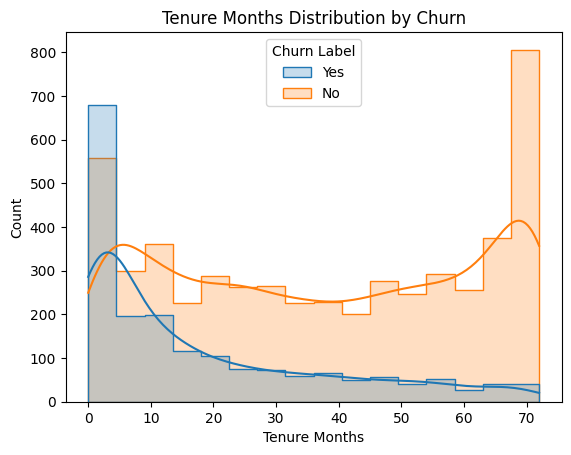

In [19]:
sns.histplot(data=df, x='Tenure Months', hue='Churn Label',
             kde=True, element='step')
plt.title('Tenure Months Distribution by Churn')
plt.show()

Lower tenure months have a much higher churn rate for lower months, and a much lower churn rate at higher months

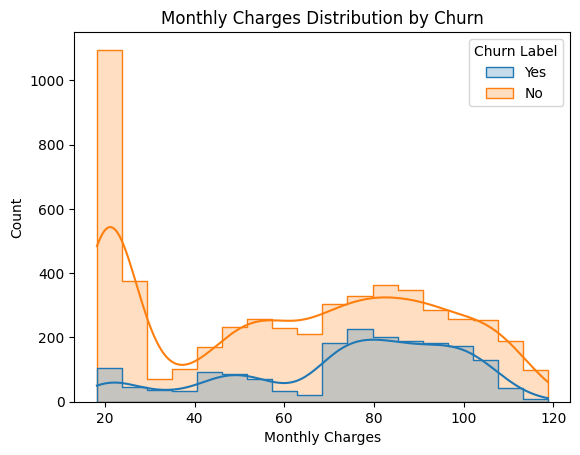

In [20]:
sns.histplot(data=df, x='Monthly Charges', hue='Churn Label',
             kde=True, element='step')
plt.title('Monthly Charges Distribution by Churn')
plt.show()

Lower costs tend to have a lower churn rate

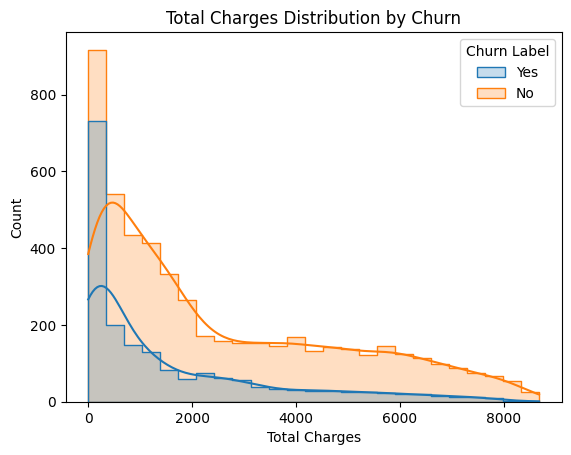

In [21]:
sns.histplot(data=df, x='Total Charges', hue='Churn Label',
             kde=True, element='step')
plt.title('Total Charges Distribution by Churn')
plt.show()

Higher total charges has a lower churn rate, most likely due to a customer having stayed for longer already, showing loyalty.

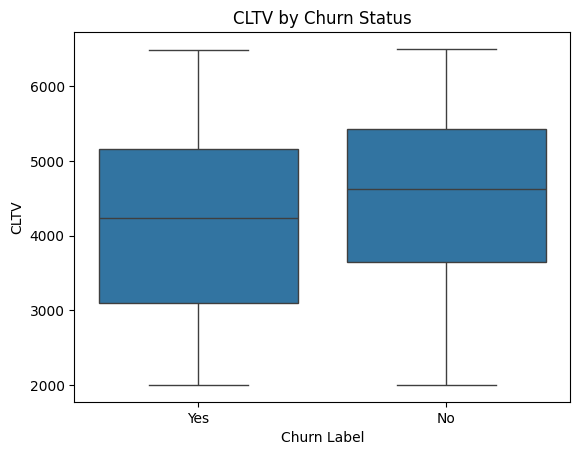

In [22]:
sns.boxplot(data=df, x='Churn Label', y='CLTV')
plt.title('CLTV by Churn Status')
plt.show()

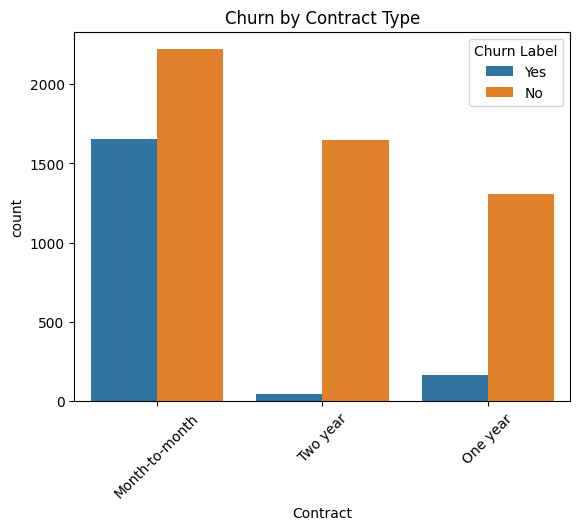

In [23]:
sns.countplot(data=df, x='Contract', hue='Churn Label')
plt.title('Churn by Contract Type')
plt.xticks(rotation=45)
plt.show()

Month-to-month contract type has a much higher churn rate.
- Month-to-month churn rate: 42.71%
- One year churn rate: 11.27%
- Two year churn rate: 2.83%

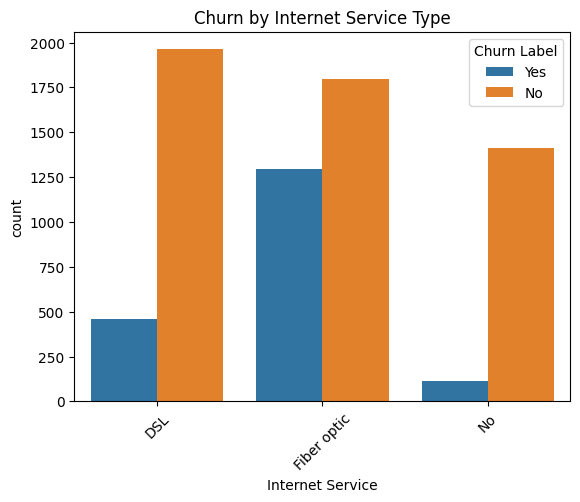

In [24]:
sns.countplot(data=df, x='Internet Service', hue='Churn Label')
plt.title('Churn by Internet Service Type')
plt.xticks(rotation=45)
plt.show()

Fiber optic internet service type has much higher churn rate
- DSL churn rate: 18.96%
- Fiber optic churn rate: 41.89%
- No internet churn rate: 7.40%

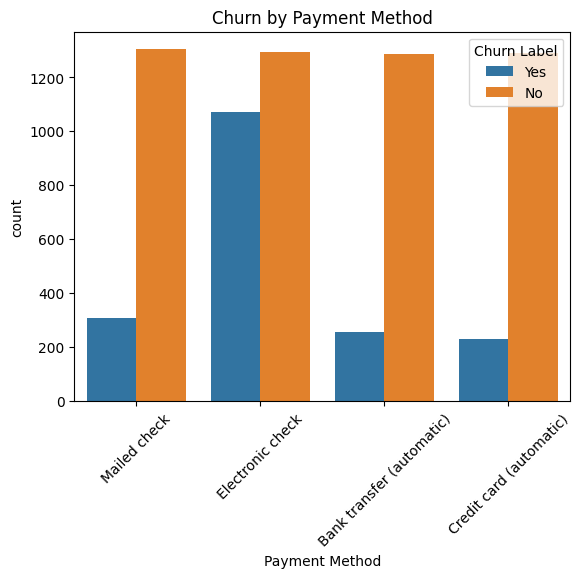

In [25]:
sns.countplot(data=df, x='Payment Method', hue='Churn Label')
plt.title('Churn by Payment Method')
plt.xticks(rotation=45)
plt.show()

Electronic check has higher churn rate
- Mailed check churn rate: 19.11%
- Electronic check churn rate: 45.29%
- Bank transfer churn rate: 16.71%
- Credit card churn rate: 15.24%

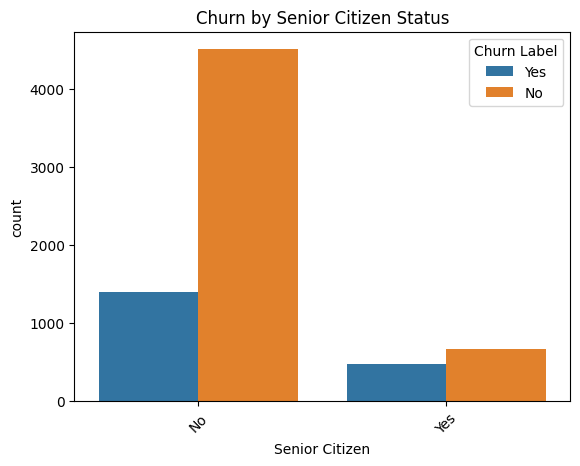

In [26]:
sns.countplot(data=df, x='Senior Citizen', hue='Churn Label')
plt.title('Churn by Senior Citizen Status')
plt.xticks(rotation=45)
plt.show()

Senior citizens have a higher churn rate
- Not senior citizen churn rate: 23.61%
- Senior citizen churn rate: 41.68%

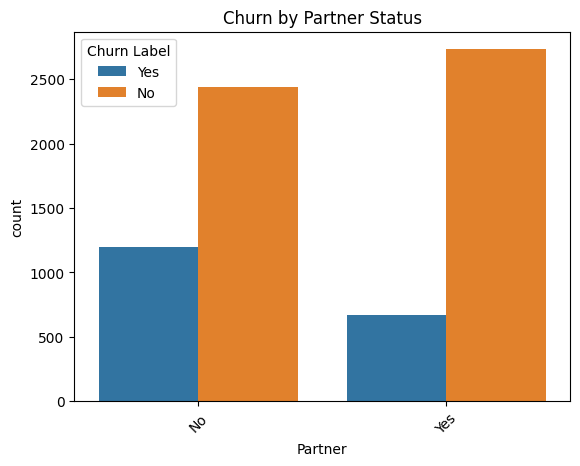

In [27]:
sns.countplot(data=df, x='Partner', hue='Churn Label')
plt.title('Churn by Partner Status')
plt.xticks(rotation=45)
plt.show()

Customers without partners have a higher churn rate
- No partner churn rate: 32.96%
- Has partner churn rate: 19.66%

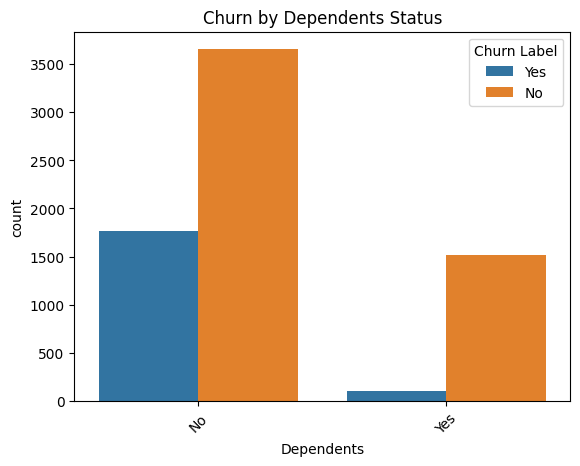

In [28]:
sns.countplot(data=df, x='Dependents', hue='Churn Label')
plt.title('Churn by Dependents Status')
plt.xticks(rotation=45)
plt.show()

Customers with no dependents have a higher churn rate than those who do.
- No dependents churn rate: 32.55%
- Has dependents churn rate: 6.52%

## Services and Their Relation to Churn

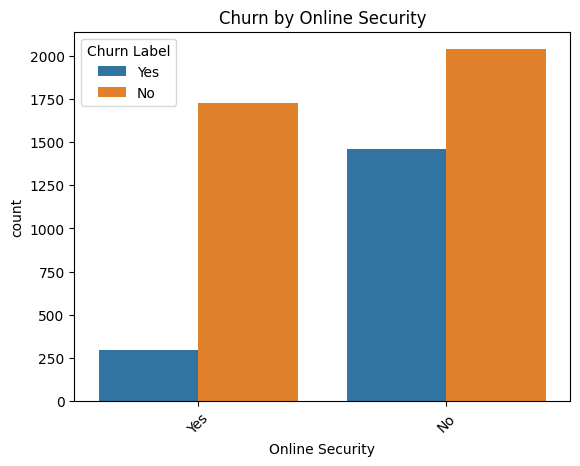

In [29]:
sns.countplot(data=df[df['Online Security'] != 'No internet service'], x='Online Security', hue='Churn Label')
plt.title('Churn by Online Security')
plt.xticks(rotation=45)
plt.show()

Customers with no online security have a higher churn rate than those who do.
- No online security churn rate: 41.77%
- Has online security churn rate: 14.61%

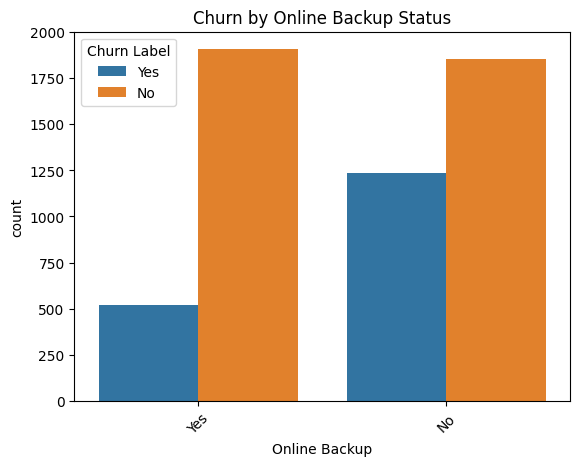

In [30]:
sns.countplot(data=df[df['Online Backup'] != 'No internet service'], x='Online Backup', hue='Churn Label')
plt.title('Churn by Online Backup Status')
plt.xticks(rotation=45)
plt.show()

Customers with no online backup have a higher churn rate.
- No online backup churn rate: 39.93%
- Has online backup churn rate: 21.53%

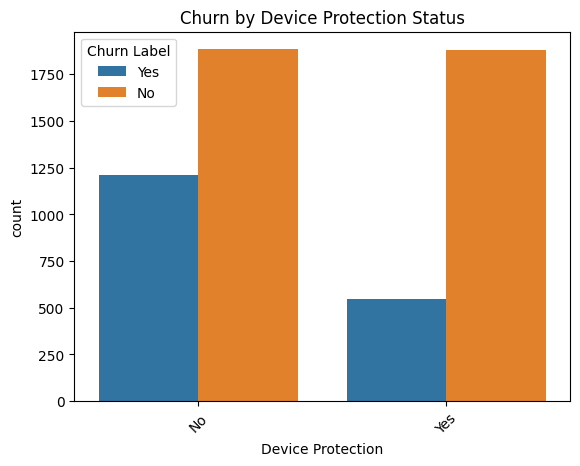

In [31]:
sns.countplot(data=df[df['Device Protection'] != 'No internet service'], x='Device Protection', hue='Churn Label')
plt.title('Churn by Device Protection Status')
plt.xticks(rotation=45)
plt.show()

Customers with no device protection have a higher churn rate.
- No device protection churn rate: 39.13%
- Has device protection churn rate: 22.50%

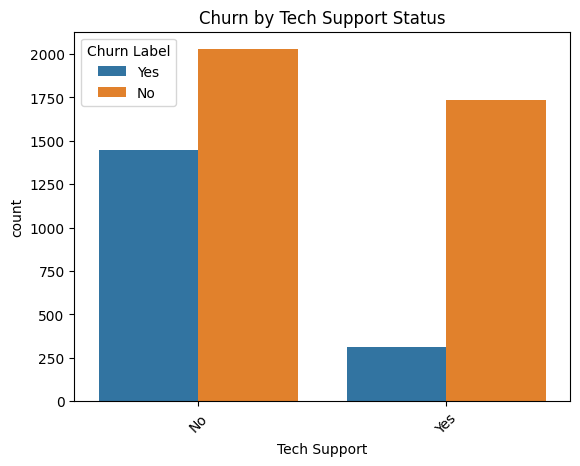

In [32]:
sns.countplot(data=df[df['Tech Support'] != 'No internet service'], x='Tech Support', hue='Churn Label')
plt.title('Churn by Tech Support Status')
plt.xticks(rotation=45)
plt.show()

Customers with no tech support have a higher churn rate.
- Has no tech support churn rate: 41.64%
- Has tech support churn rate: 15.17%

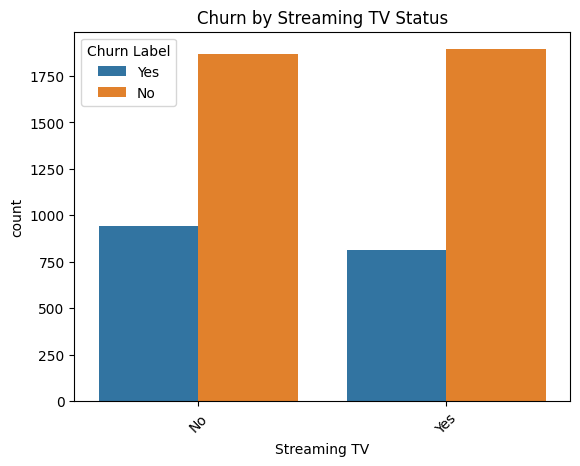

In [33]:
sns.countplot(data=df[df['Streaming TV'] != 'No internet service'], x='Streaming TV', hue='Churn Label')
plt.title('Churn by Streaming TV Status')
plt.xticks(rotation=45)
plt.show()

Streaming TV services doesn't differentiate churn rate by much.
- Streams TV churn rate: 30.07%
- Doesn't stream tv churn rate: 33.52%

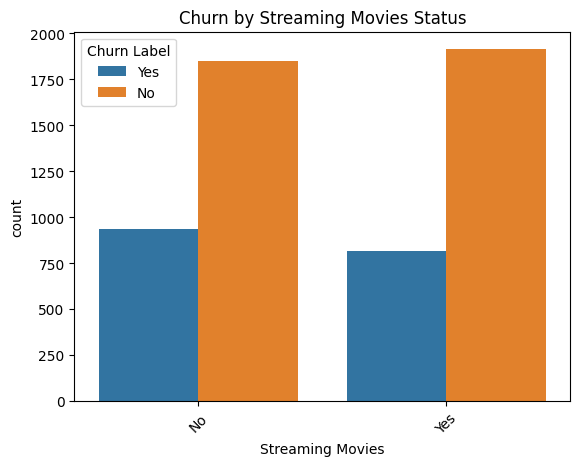

In [34]:
sns.countplot(data=df[df['Streaming Movies'] != 'No internet service'], x='Streaming Movies', hue='Churn Label')
plt.title('Churn by Streaming Movies Status')
plt.xticks(rotation=45)
plt.show()

Streaming movies services doesn't differentiate churn rate by much.
- Streams movies churn rate: 29.94%
- Doesn't stream movies churn rate: 33.68%

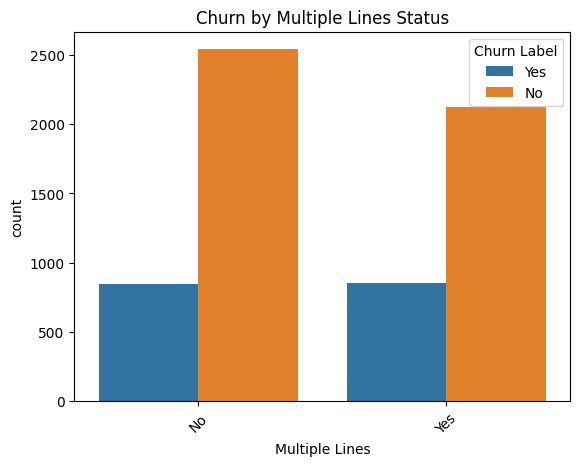

In [35]:
sns.countplot(data=df[df['Multiple Lines'] != 'No phone service'], x='Multiple Lines', hue='Churn Label')
plt.title('Churn by Multiple Lines Status')
plt.xticks(rotation=45)
plt.show()

Having multiple lines doesn't differentiate churn rate by much.
- Has multiple lines churn rate: 28.61%
- Doesn't have multiple lines churn rate: 25.04%

Across all services offerings, it appears that a lack of services, especially tech support, device protection, and online backup, result in a much higher churn rate.

## Categorical Features and Their Churn Rates Listed

In [36]:
for col in categorical_cols:
    print(f'\n--- {col} ---')
    print(
        pd.crosstab(
            df[col],
            df['Churn Label'],
            normalize='index'
        ) * 100
    )


--- Gender ---
Churn Label         No        Yes
Gender                           
Female       73.079128  26.920872
Male         73.839662  26.160338

--- Senior Citizen ---
Churn Label            No        Yes
Senior Citizen                      
No              76.393832  23.606168
Yes             58.318739  41.681261

--- Partner ---
Churn Label         No        Yes
Partner                          
No           67.042021  32.957979
Yes          80.335097  19.664903

--- Dependents ---
Churn Label         No        Yes
Dependents                       
No           67.448301  32.551699
Yes          93.484942   6.515058

--- Phone Service ---
Churn Label           No        Yes
Phone Service                      
No             75.073314  24.926686
Yes            73.290363  26.709637

--- Multiple Lines ---
Churn Label              No        Yes
Multiple Lines                        
No                74.955752  25.044248
No phone service  75.073314  24.926686
Yes               71

## Numeric Features Correlation

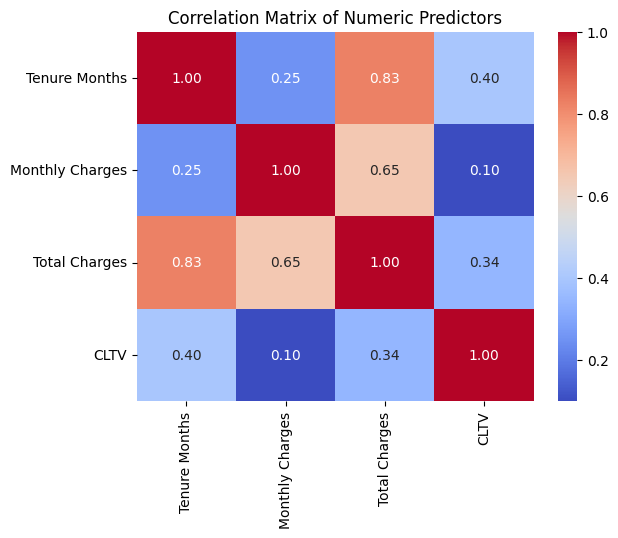

In [37]:
numeric_predictors = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

sns.heatmap(
    df[numeric_predictors].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix of Numeric Predictors')
plt.show()

Correlations between numeric features is only seen mostly between charges and tenure months.

Notable features for identifying churn rate:
- Tenure months
- Monthly charges
- Total charges
- Contract Type
- Internet Service type
- Payment Method
- Senior Citizen
- Dependents
- Online Security
- Online Backup
- Device Protection
- Tech Support

# Training and Testing Data

Explanation for columns being dropped:
- Lat Long: Combines data from longitude and latitude
- Longitude: Customers are concetrated in California, latitude and longitude aren't important to churn after eda investigation
- Latitude: Same as Longitude
- CustomerID: Just a method to identify customers, not neded to predict churn
- Country: All customers are domestic
- Churn Label: This is the class, not needed for prediction
- Count: Count of customers not needed
- Churn Score: This score was made using an IBM prediction system, results in data leakage, removed
- Churn Reason: Data leakage, as only customers who have churned have a churn reason
- CLTV: Customer lifetime value. This feature is good for deciding what customers to prioritize, but not needed to predict churn
- City: Lots of cities have below 20 customers, these low numbers make cities an unreliable metric for predicting churn.
- Zip code: Same case but more extreme as city

In [38]:
drop_cols = ['CustomerID', 'Country', 'Lat Long', 'Churn Label', 'Churn Value', 'Count',
             'Churn Score', 'Churn Reason', 'CLTV', 'State', 'City', 'Zip Code', 'Latitude', 'Longitude']

X = df.drop(columns=drop_cols)
y = df['Churn Value']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y
)

# Predictive Modeling and Interpretation

This section extends the existing analysis into predictive modeling. The goal is to predict whether a customer will churn and compare three classification approaches using the customer information retained after the exploratory analysis. The emphasis is on the predictive accuracy of the models for previously unseen customers rather than on fitting the existing data as well as possible. Logistic regression, k-nearest neighbors and random forest models are three different approaches to the binary classification to compare.


In [40]:
numeric_features = X_train.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric_features),
    ("categorical",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical_features)
])

print("Numeric predictors:",numeric_features)
print("Categorical predictors:",categorical_features)


Numeric predictors: ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categorical predictors: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


## Baseline Model



In [43]:
baseline_model = DummyClassifier(strategy="most_frequent",random_state=1)

baseline_model.fit(X_train, y_train)
baseline_prediction = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test,baseline_prediction)

print(f"Baseline validation accuracy: {baseline_accuracy:.3f}")


Baseline validation accuracy: 0.735


## Logistic Regression

Logistic regression is a simple classification model and provides a baseline for comparing the other models. Because churn is imbalanced, class weights are used to give more importance to the churn class. The regularization parameter C is tuned using five-fold cross-validation with ROC AUC as the scoring metric.


In [45]:
logistic_pipeline = Pipeline([("preprocessor",preprocessor),("model",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=1))])

logistic_grid = GridSearchCV(logistic_pipeline,param_grid={"model__C":[0.1,1,10]},scoring="roc_auc",cv=5,n_jobs=-1)
logistic_grid.fit(X_train,y_train)

logistic_validation_probability = logistic_grid.predict_proba(X_test)[:,1]
logistic_validation_prediction = (logistic_validation_probability >= 0.50).astype(int)

print("Best logistic regression parameters:")
print(logistic_grid.best_params_)


Best logistic regression parameters:
{'model__C': 1}


### Validation Results


In [46]:
logistic_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                                 "Validation":[accuracy_score(y_test,logistic_validation_prediction),
                                               precision_score(y_test,logistic_validation_prediction),
                                               recall_score(y_test,logistic_validation_prediction),
                                               f1_score(y_test,logistic_validation_prediction),
                                               roc_auc_score(y_test,logistic_validation_probability)]})

display(logistic_results)

,Metric,Validation
0,Accuracy,0.759796
1,Precision,0.530986
2,Recall,0.807281
3,F1,0.640612
4,ROC AUC,0.853129


The logistic regression model had a validation ROC AUC of around 0.853. This means that the model was generally able to distinguish between customers that churned and those that did not. Its recall was around 80.7%, which means the model was able to find most of the actual churn cases in the validation data. But the accuracy of it was about 76.0%, so there were still a fair number of incorrect classifications. The results suggest the logistic regression was particularly useful to identify potential churners but have to compare the performance with other models to select the final model.


## k-Nearest Neighbors

k-NN classifies a customer using the outcomes of nearby observations in predictor space. The number of neighbors and weighting method are tuned using five-fold cross-validation. A small set of candidate values is used to keep the analysis straightforward while still testing whether the neighborhood size affects predictive performance.


In [47]:
knn_pipeline = Pipeline([("preprocessor",preprocessor),("model",KNeighborsClassifier())])

knn_grid = GridSearchCV(knn_pipeline,param_grid={"model__n_neighbors":[5,15,25],"model__weights":["uniform","distance"]},scoring="roc_auc",cv=5,n_jobs=-1)
knn_grid.fit(X_train,y_train)

knn_validation_probability = knn_grid.predict_proba(X_test)[:,1]
knn_validation_prediction = (knn_validation_probability >= 0.50).astype(int)

print("Best k-NN parameters:")
print(knn_grid.best_params_)

Best k-NN parameters:
{'model__n_neighbors': 25, 'model__weights': 'uniform'}


### Validation Results


In [48]:
knn_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                            "Validation":[accuracy_score(y_test,knn_validation_prediction),
                                          precision_score(y_test,knn_validation_prediction),
                                          recall_score(y_test,knn_validation_prediction),
                                          f1_score(y_test,knn_validation_prediction),
                                          roc_auc_score(y_test,knn_validation_probability)]})

display(knn_results)


,Metric,Validation
0,Accuracy,0.797842
1,Precision,0.627002
2,Recall,0.586724
3,F1,0.606195
4,ROC AUC,0.838297


### Interpretation

k-NN provides a different approach by classifying customers based on similarity to other customers. In this dataset, the model achieved a validation ROC AUC of about 0.838 and recall of about 58.6%, meaning it identified fewer actual churners than logistic regression. The model also requires both numeric variables to be standardized and categorical variables to be one-hot encoded, which is especially important here because the dataset contains many categorical customer and service variables.


## Random Forest

Random forest is included as exploratory analysis because churn may depend on combinations of contract type, tenure, charges and service characteristics. These relationships may not be well described by a single linear boundary. The model is tuned on a small grid of tree depth and minimum leaf size with number of trees fixed at 200.


In [50]:
random_forest_pipeline = Pipeline([("preprocessor",preprocessor),("model",RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=1,n_jobs=-1))])

random_forest_grid = GridSearchCV(random_forest_pipeline,param_grid={"model__max_depth":[5,10,None],"model__min_samples_leaf":[1,5]},scoring="roc_auc",cv=5,n_jobs=-1)
random_forest_grid.fit(X_train,y_train)

rf_validation_probability = random_forest_grid.predict_proba(X_test)[:,1]
rf_validation_prediction = (rf_validation_probability >= 0.50).astype(int)

print("Best random forest parameters:")
print(random_forest_grid.best_params_)

Best random forest parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 5}


### Validation Results


In [52]:
rf_results = pd.DataFrame({"Metric":["Accuracy","Precision","Recall","F1","ROC AUC"],
                           "Validation":[accuracy_score(y_test,rf_validation_prediction),
                                         precision_score(y_test,rf_validation_prediction),
                                         recall_score(y_test,rf_validation_prediction),
                                         f1_score(y_test,rf_validation_prediction),
                                         roc_auc_score(y_test,rf_validation_probability)]})

display(rf_results)


,Metric,Validation
0,Accuracy,0.773992
1,Precision,0.552672
2,Recall,0.775161
3,F1,0.645276
4,ROC AUC,0.855119


The random forest performed well on the validation data, with a ROC AUC of about 0.855, recall of about 77.5%, and F1 score of about 64.5%. This means it was able to identify a large portion of the customers who actually churned while maintaining a similar overall performance to logistic regression.


## Compare Models

The models are compared using the same validation data. ROC AUC is the primary comparison measure. F1, recall, precision, and accuracy are also reported to show the trade-offs at the 0.50 classification cutoff.


In [55]:
model_comparison = pd.DataFrame({
    "Model":["Logistic Regression","k-NN","Random Forest"],
    "Accuracy":[accuracy_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "Precision":[precision_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "Recall":[recall_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "F1":[f1_score(y_test,p) for p in [logistic_validation_prediction,knn_validation_prediction,rf_validation_prediction]],
    "ROC AUC":[roc_auc_score(y_test,p) for p in [logistic_validation_probability,knn_validation_probability,rf_validation_probability]]
})

display(model_comparison.sort_values("ROC AUC",ascending=False).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Random Forest,0.773992,0.552672,0.775161,0.645276,0.855119
1,Logistic Regression,0.759796,0.530986,0.807281,0.640612,0.853129
2,k-NN,0.797842,0.627002,0.586724,0.606195,0.838297


Logistic regression had the highest recall at about 80.7%, while k-NN had the lowest recall at about 58.6% and a ROC AUC of about 0.838. Random forest had the highest ROC AUC at about 0.855, with a recall of about 77.5% and an F1 score of about 64.5%. Based on these results, random forest was selected because it provided the strongest overall ability to distinguish between customers who churned and those who did not. This decision is based on the validation performance of the models, and the variables identified by the model should be viewed as useful predictors.


In [56]:
selected_model_name = "Random Forest"
selected_model = random_forest_grid.best_estimator_

print(f"Selected model: {selected_model_name}")
print(f"Best parameters: {random_forest_grid.best_params_}")


Selected model: Random Forest
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5}
